# University of Kerala – Affiliated Colleges Web Scraping Project

Scrapes the affiliated-college directory of the University of Kerala, collects contact details for each college, enriches the data with district / establishment year / college type, validates it, explores it, and exports a final CSV.

**Pipeline:** directory page → college IDs → detail pages → enrichment → validation → EDA → final cleaned CSV

In [1]:
import re
import time

import matplotlib.pyplot as plt
import pandas as pd
import requests
from bs4 import BeautifulSoup
from urllib.parse import urljoin

DIRECTORY_URL = "https://www.keralauniversity.ac.in/affiliated-colleges"
HEADERS = {"User-Agent": "Mozilla/5.0 (compatible; StudentResearch/1.0)"}

## 1. Fetch the College Directory Page

In [2]:
response = requests.get(
    DIRECTORY_URL,
    headers=HEADERS,
    timeout=30
)

print("Status code:", response.status_code)
print("Final URL:", response.url)
print("HTML length:", len(response.text))

response.raise_for_status()

soup = BeautifulSoup(response.text, "html.parser")

print("Page title:", soup.title.get_text(strip=True))

Status code: 200
Final URL: https://www.keralauniversity.ac.in/affiliated-colleges
HTML length: 601488
Page title: University of Kerala


## 2. Extract College Names and IDs

In [3]:
all_h4 = soup.find_all("h4")

college_records = []

for heading in all_h4:
    name = heading.get_text(" ", strip=True)

    container = heading.find_parent(
        "div",
        class_="school-list-item"
    )

    if container:
        form = container.find(
            "form",
            attrs={"name": "CollegeDetailsForm"}
        )

        if form:
            college_id = form.find(
                "input",
                attrs={"name": "collegeCol"}
            )

            if college_id:
                college_records.append({
                    "College Name": name,
                    "College ID": college_id.get("value")
                })

print("College records found:", len(college_records))

for record in college_records[:10]:
    print(record)

College records found: 204
{'College Name': 'A. J. College of Science and Technology, Thonnakkal', 'College ID': '5'}
{'College Name': "All Saints' College, Thiruvananthapuram", 'College ID': '4'}
{'College Name': 'Allama Iqbal Institute of Management, Peringamala, Thiruvananthapuram', 'College ID': '59'}
{'College Name': 'Ayyankali Memorial Arts and Science College, Kuryottumala, Vettithitta P. O., Pathanapuram', 'College ID': '231'}
{'College Name': 'B.N.V. College of Teacher Education, Thiruvallam, Thiruvananthapuram', 'College ID': '170'}
{'College Name': 'Baby John Memorial Govt. College, Chavara', 'College ID': '229'}
{'College Name': 'Badhiriya B.Ed. Training College, Velichikkala, Kollam', 'College ID': '87'}
{'College Name': 'Baselios Marthoma Mathews II Training College, Kottarakara', 'College ID': '130'}
{'College Name': 'Bishop Jerome School of Architecture, Fathima College Road, Kollam', 'College ID': '271'}
{'College Name': 'Bishop Jesudasan CSI Arts & Science College, Mu

## 3. Scrape Each College's Contact Details

Each college has a details page (requested with a POST using its college ID). The function below extracts the address, phone number(s), email and website.

In [4]:
details_url = (
    "https://www.keralauniversity.ac.in/"
    "affiliated-college-details"
)

def extract_college_details(session, record):

    college_name = record["College Name"]
    college_id = record["College ID"]

    result = {
        "College Name": college_name,
        "College ID": college_id,
        "Address": None,
        "Contact Number": None,
        "Email Address": None,
        "Website URL": None,
        "Status": "Not processed"
    }

    try:
        response = session.post(
            details_url,
            data={"collegeCol": college_id},
            timeout=30
        )

        response.raise_for_status()

        page = BeautifulSoup(
            response.text,
            "html.parser"
        )

        contact_span = next(
            (
                span
                for span in page.find_all("span")
                if "Contact Address" in span.get_text(
                    " ", strip=True
                )
            ),
            None
        )

        if not contact_span:
            result["Status"] = "Contact section not found"
            return result

        text = contact_span.get_text(" ", strip=True)

        address_match = re.search(
            r"Contact Address\s*:\s*(.*?)"
            r"(?=\s*Contact No\s*:|\s*Email\s*:|"
            r"\s*Web URL\s*:|\s*Courses Offered\s*:|$)",
            text,
            re.IGNORECASE
        )

        if address_match:
            address = address_match.group(1).strip()
            result["Address"] = address or None

        phone_match = re.search(
            r"Contact No\s*:\s*(.*?)"
            r"(?=\s*Email\s*:|\s*Web URL\s*:|"
            r"\s*Courses Offered\s*:|$)",
            text,
            re.IGNORECASE
        )

        if phone_match:
            phone_text = phone_match.group(1)

            numbers = re.findall(
                r"\+?\d[\d\s()-]{4,}\d",
                phone_text
            )

            cleaned_numbers = [
                " ".join(number.split())
                for number in numbers
            ]

            result["Contact Number"] = (
                " | ".join(cleaned_numbers)
                if cleaned_numbers
                else None
            )

        email_match = re.search(
            r"[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}",
            text
        )

        if email_match:
            result["Email Address"] = email_match.group(0)

        website_match = re.search(
            r"Web URL\s*:\s*(.*?)"
            r"(?=\s*Courses Offered\s*:|$)",
            text,
            re.IGNORECASE
        )

        if website_match:
            website_text = website_match.group(1).strip()

            website_link = contact_span.find(
                "a",
                href=lambda href: (
                    href
                    and not href.lower().startswith(
                        ("mailto:", "tel:", "javascript:")
                    )
                    and "keralauniversity.ac.in" not in href.lower()
                    and "exams.keralauniversity.ac.in" not in href.lower()
                )
            )

            if website_link:
                result["Website URL"] = urljoin(
                    details_url,
                    website_link["href"].strip()
                )
            elif website_text:
                result["Website URL"] = website_text

        result["Status"] = "Success"

    except requests.RequestException as error:
        result["Status"] = f"Request error: {error}"

    return result

In [5]:
session = requests.Session()

session.headers.update(HEADERS)

test_record = college_records[0]

test_result = extract_college_details(
    session,
    test_record
)

for key, value in test_result.items():
    print(f"{key}: {value}")

College Name: A. J. College of Science and Technology, Thonnakkal
College ID: 5
Address: The Principal, A.J. college of Science and Technology, Thonnakkal, Thiruvananthapuram, Kerala - 695 317
Contact Number: 0471 2618644 | 0471 2618106
Email Address: ajcollegeprincipal@gmail.com
Website URL: http://www.ajcollege.in
Status: Success


Run the scraper for all colleges (with a short pause between requests to be polite to the server).

In [6]:
import pandas as pd
import time

all_college_details = []

for i, record in enumerate(college_records, start=1):
    details = extract_college_details(session, record)
    all_college_details.append(details)

    print(
        f"Processed {i}/{len(college_records)}: "
        f"{record['College Name']} - {details['Status']}"
    )

    time.sleep(0.5)

df = pd.DataFrame(all_college_details)

display(df.head())

print("Total records:", len(df))

Processed 1/204: A. J. College of Science and Technology, Thonnakkal - Success
Processed 2/204: All Saints' College, Thiruvananthapuram - Success
Processed 3/204: Allama Iqbal Institute of Management, Peringamala, Thiruvananthapuram - Success
Processed 4/204: Ayyankali Memorial Arts and Science College, Kuryottumala, Vettithitta P. O., Pathanapuram - Success
Processed 5/204: B.N.V. College of Teacher Education, Thiruvallam, Thiruvananthapuram - Success
Processed 6/204: Baby John Memorial Govt. College, Chavara - Success
Processed 7/204: Badhiriya B.Ed. Training College, Velichikkala, Kollam - Success
Processed 8/204: Baselios Marthoma Mathews II Training College, Kottarakara - Success
Processed 9/204: Bishop Jerome School of Architecture, Fathima College Road, Kollam - Success
Processed 10/204: Bishop Jesudasan CSI Arts & Science College, Mulayara, Thiruvananthapuram - Success
Processed 11/204: Bishop Moore College for the Hearing Impaired, Manakala, Adoor - Success
Processed 12/204: B

,College Name,College ID,Address,Contact Number,Email Address,Website URL,Status
0,"A. J. College of Science and Technology, Thonn...",5,"The Principal, A.J. college of Science and Tec...",0471 2618644 | 0471 2618106,ajcollegeprincipal@gmail.com,http://www.ajcollege.in,Success
1,"All Saints' College, Thiruvananthapuram",4,None,0471 2501153 | 2503821 | 0471 2503821,allsaintscolegeasc@gmail.com,http://www.allsaintscollege.ac.in,Success
2,"Allama Iqbal Institute of Management, Peringam...",59,"The Principal, Allama Iqbal Institute of Manag...",0472 2846724 | 0474 2182071,aiimmba@hotmail.com,http://www.aimmba.com,Success
3,"Ayyankali Memorial Arts and Science College, K...",231,"The Principal, Ayyankali Memorial Arts and Sci...",0475 2220555,akmasprincipal@gmail.com,http://www.akmascollege.com,Success
4,"B.N.V. College of Teacher Education, Thiruvall...",170,None,0471 2382063 | 0471 2382063,bnv.teachereducation@gmail.com,http://www.bnvtrust.org,Success


Total records: 204


Save the scraped data.

In [7]:
df.to_csv(
    "kerala_university_colleges.csv",
    index=False,
    encoding="utf-8-sig"
)

df.to_excel(

    "kerala_university_colleges.xlsx",
    index=False
)

print("CSV and Excel files saved successfully!")

CSV and Excel files saved successfully!


## 4. Enrich the Data (District, Establishment Year, College Type)

These fields come from the directory page itself, so we reuse the page we already downloaded.

In [8]:
college_items = soup.select("div.school-list-item")

print("College entries found:", len(college_items))

extra_records = []

for item in college_items:

    heading = item.find("h4")
    form = item.find("form", {"name": "CollegeDetailsForm"})

    if heading is None or form is None:
        continue

    id_input = form.find("input", {"name": "collegeCol"})

    if id_input is None:
        continue

    college_name = heading.get_text(" ", strip=True)
    college_id = str(id_input.get("value", "")).strip()

    text = item.get_text(" ", strip=True)

    district = None
    establishment_year = None
    college_type = None

    match = re.search(
        r"Estd\.\s*(\d{4})\s*\|\s*"
        r"(Government\s+Self Financing|"
        r"Self Financing|Government|Aided|Autonomous)\b",
        text,
        re.IGNORECASE
    )

    if match:

        establishment_year = match.group(1)
        college_type = match.group(2).strip()

        prefix = text[:match.start()]

        if prefix.startswith(college_name):
            district_text = prefix[len(college_name):]
        else:
            district_text = prefix

        district_text = district_text.strip(" |,-")

        district = district_text if district_text else None

    extra_records.append({
        "College ID": college_id,
        "Directory College Name": college_name,
        "District": district,
        "Establishment Year": establishment_year,
        "College Type": college_type
    })

directory_df = pd.DataFrame(extra_records)

display(directory_df.head(10))

print("\nExtra records collected:", len(directory_df))

print("\nMissing values in the extracted fields:")
print(
    directory_df[
        ["District", "Establishment Year", "College Type"]
    ].isna().sum()
)

print(
    "\nDuplicate college IDs:",
    directory_df["College ID"].duplicated().sum()
)

College entries found: 204


,College ID,Directory College Name,District,Establishment Year,College Type
0,5,"A. J. College of Science and Technology, Thonn...",Thiruvananthapuram,1995,Self Financing
1,4,"All Saints' College, Thiruvananthapuram",Thiruvananthapuram,1964,Aided
2,59,"Allama Iqbal Institute of Management, Peringam...",Thiruvananthapuram,2003,Self Financing
3,231,"Ayyankali Memorial Arts and Science College, K...",Kollam,2015,Aided
4,170,"B.N.V. College of Teacher Education, Thiruvall...",Thiruvananthapuram,2005,Self Financing
5,229,"Baby John Memorial Govt. College, Chavara",Kollam,1981,Government
6,87,"Badhiriya B.Ed. Training College, Velichikkala...",Kollam,2007,Self Financing
7,130,"Baselios Marthoma Mathews II Training College,...",Kollam,1995,Self Financing
8,271,"Bishop Jerome School of Architecture, Fathima ...",Kollam,2010,Self Financing
9,279,"Bishop Jesudasan CSI Arts & Science College, M...",Thiruvananthapuram,2017,Aided



Extra records collected: 204

Missing values in the extracted fields:
District              8
Establishment Year    8
College Type          8
dtype: int64

Duplicate college IDs: 0


In [9]:
df["College ID"] = df["College ID"].astype(str).str.strip()
directory_df["College ID"] = (
    directory_df["College ID"].astype(str).str.strip()
)

extra_columns = directory_df[
    [
        "College ID",
        "District",
        "Establishment Year",
        "College Type"
    ]
]

df_updated = df.merge(
    extra_columns,
    on="College ID",
    how="left",
    validate="one_to_one"
)

print("Original rows:", len(df))
print("Updated rows:", len(df_updated))

display(df_updated.head())

print("\nMissing values after merge:")
print(
    df_updated[
        ["District", "Establishment Year", "College Type"]
    ].isna().sum()
)

Original rows: 204
Updated rows: 204


,College Name,College ID,Address,Contact Number,Email Address,Website URL,Status,District,Establishment Year,College Type
0,"A. J. College of Science and Technology, Thonn...",5,"The Principal, A.J. college of Science and Tec...",0471 2618644 | 0471 2618106,ajcollegeprincipal@gmail.com,http://www.ajcollege.in,Success,Thiruvananthapuram,1995,Self Financing
1,"All Saints' College, Thiruvananthapuram",4,None,0471 2501153 | 2503821 | 0471 2503821,allsaintscolegeasc@gmail.com,http://www.allsaintscollege.ac.in,Success,Thiruvananthapuram,1964,Aided
2,"Allama Iqbal Institute of Management, Peringam...",59,"The Principal, Allama Iqbal Institute of Manag...",0472 2846724 | 0474 2182071,aiimmba@hotmail.com,http://www.aimmba.com,Success,Thiruvananthapuram,2003,Self Financing
3,"Ayyankali Memorial Arts and Science College, K...",231,"The Principal, Ayyankali Memorial Arts and Sci...",0475 2220555,akmasprincipal@gmail.com,http://www.akmascollege.com,Success,Kollam,2015,Aided
4,"B.N.V. College of Teacher Education, Thiruvall...",170,None,0471 2382063 | 0471 2382063,bnv.teachereducation@gmail.com,http://www.bnvtrust.org,Success,Thiruvananthapuram,2005,Self Financing



Missing values after merge:
District              8
Establishment Year    8
College Type          8
dtype: int64


In [10]:
df_updated.to_csv(
    "kerala_university_colleges_enriched.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Updated dataset saved successfully!")

Updated dataset saved successfully!


## 5. Data Validation

Basic checks on email format and phone-number length (these do not prove the details are active or current).

In [11]:
df_clean = df_updated.copy()

text_columns = [
    "College Name",
    "Address",
    "Contact Number",
    "Email Address",
    "Website URL",
    "District",
    "College Type"
]

for column in text_columns:
    df_clean[column] = df_clean[column].apply(
        lambda value: (
            value.strip()
            if isinstance(value, str)
            else value
        )
    )

df_clean[text_columns] = df_clean[text_columns].replace(
    r"^\s*$", pd.NA, regex=True
)

def valid_email(value):
    if pd.isna(value):
        return pd.NA

    return bool(
        re.fullmatch(
            r"[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}",
            str(value).strip()
        )
    )

df_clean["Email Format Valid"] = (
    df_clean["Email Address"].apply(valid_email)
)

def validate_phone_group(value):
    if pd.isna(value):
        return pd.NA

    numbers = str(value).split("|")
    results = []

    for number in numbers:
        digits = re.sub(r"\D", "", number)

        results.append(7 <= len(digits) <= 13)

    return all(results)

df_clean["Phone Format Plausible"] = (
    df_clean["Contact Number"].apply(validate_phone_group)
)

print("Total records:", len(df_clean))

print("\nEmail format results:")
print(df_clean["Email Format Valid"].value_counts(dropna=False))

print("\nPhone format results:")
print(df_clean["Phone Format Plausible"].value_counts(dropna=False))

print("\nEmails requiring review:")
display(
    df_clean[
        df_clean["Email Format Valid"] == False
    ][["College Name", "Email Address"]]
)

print("\nPhone numbers requiring review:")
display(
    df_clean[
        df_clean["Phone Format Plausible"] == False
    ][["College Name", "Contact Number"]]
)

Total records: 204

Email format results:
Email Format Valid
True    178
<NA>     26
Name: count, dtype: int64

Phone format results:
Phone Format Plausible
True    191
<NA>     13
Name: count, dtype: int64

Emails requiring review:


,College Name,Email Address



Phone numbers requiring review:


,College Name,Contact Number


## 6. Exploratory Data Analysis and Visualizations

Exploratory Data Analysis (EDA) was performed on the enriched dataset containing 204 college records. Three visualizations were created using Matplotlib and Pandas to examine missing values, contact-information completeness, and college-type distribution.

Total college records: 204


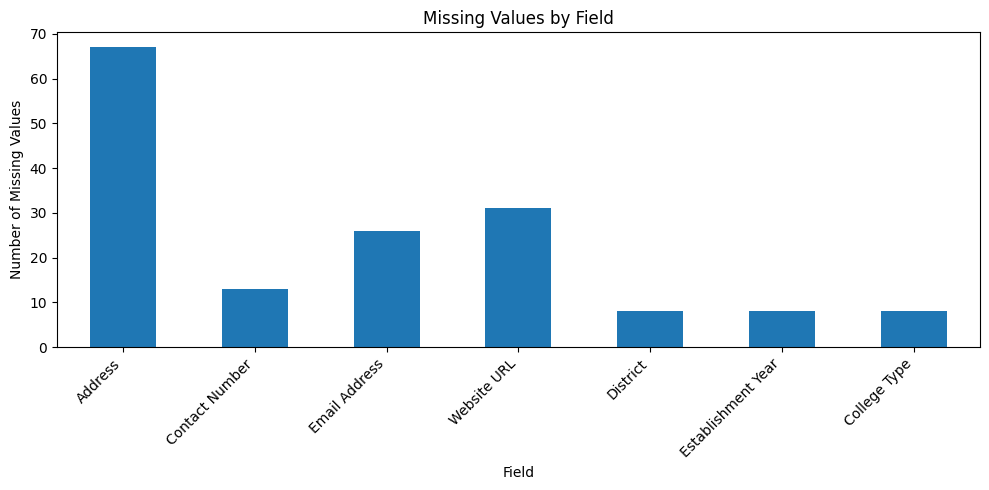

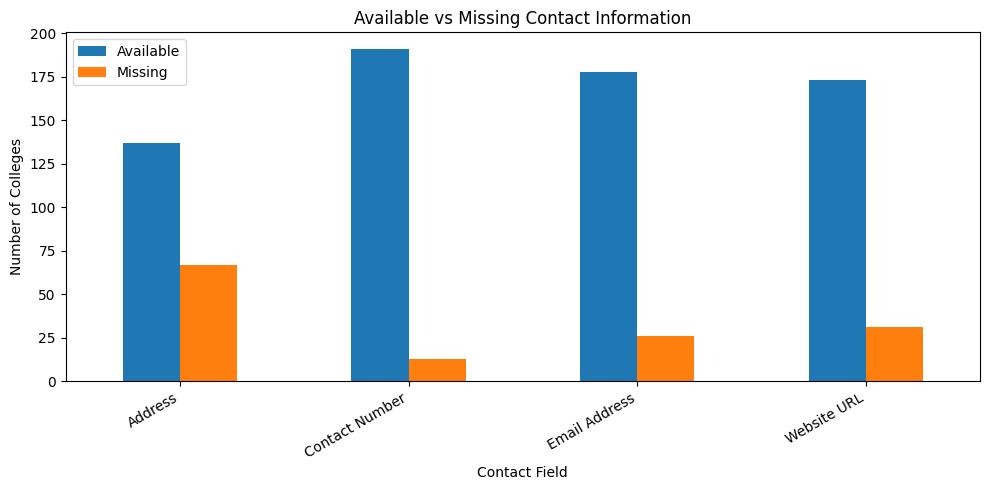

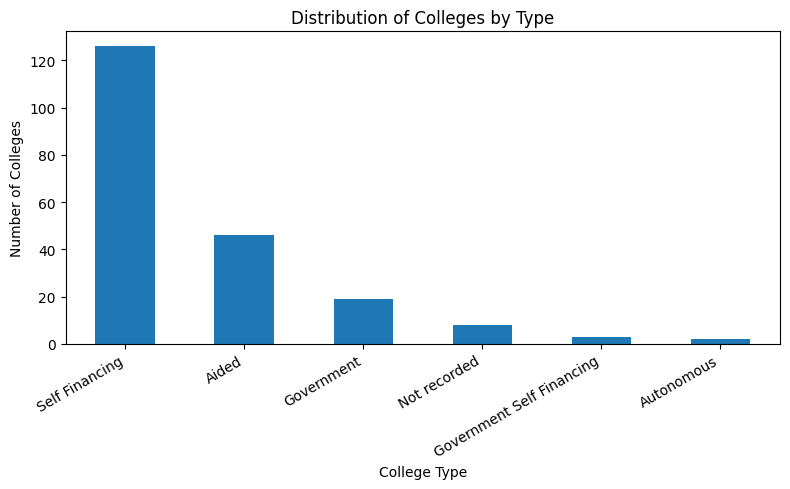

In [12]:
print("Total college records:", len(df_clean))

fields = [
    "Address",
    "Contact Number",
    "Email Address",
    "Website URL",
    "District",
    "Establishment Year",
    "College Type"
]

missing_counts = df_clean[fields].isna().sum()

plt.figure(figsize=(10, 5))
missing_counts.plot(kind="bar")
plt.title("Missing Values by Field")
plt.xlabel("Field")
plt.ylabel("Number of Missing Values")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

contact_fields = [
    "Address",
    "Contact Number",
    "Email Address",
    "Website URL"
]

available = df_clean[contact_fields].notna().sum()
missing = df_clean[contact_fields].isna().sum()

comparison = pd.DataFrame({
    "Available": available,
    "Missing": missing
})

comparison.plot(kind="bar", figsize=(10, 5))
plt.title("Available vs Missing Contact Information")
plt.xlabel("Contact Field")
plt.ylabel("Number of Colleges")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

type_counts = (
    df_clean["College Type"]
    .fillna("Not recorded")
    .value_counts()
)

plt.figure(figsize=(8, 5))
type_counts.plot(kind="bar")
plt.title("Distribution of Colleges by Type")
plt.xlabel("College Type")
plt.ylabel("Number of Colleges")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

In [13]:
print("CONTACT INFORMATION SUMMARY")
for field in [
    "Address",
    "Contact Number",
    "Email Address",
    "Website URL"
]:
    available_count = df_clean[field].notna().sum()
    missing_count = df_clean[field].isna().sum()

    print(
        f"{field}: "
        f"{available_count} available, "
        f"{missing_count} missing"
    )

print("\nCOLLEGE TYPE SUMMARY")
print(
    df_clean["College Type"]
    .fillna("Not recorded")
    .value_counts()
)

print("\nDISTRICT SUMMARY")
print(
    df_clean["District"]
    .fillna("Not recorded")
    .value_counts()
)

CONTACT INFORMATION SUMMARY
Address: 137 available, 67 missing
Contact Number: 191 available, 13 missing
Email Address: 178 available, 26 missing
Website URL: 173 available, 31 missing

COLLEGE TYPE SUMMARY
College Type
Self Financing               126
Aided                         46
Government                    19
Not recorded                   8
Government Self Financing      3
Autonomous                     2
Name: count, dtype: int64

DISTRICT SUMMARY
District
Thiruvananthapuram    88
Kollam                61
Alappuzha             34
Pathanamthitta        13
Not recorded           8
Name: count, dtype: int64


### 6.1 Missing Values by Field

The missing-value analysis showed that address information had the highest number of missing values, with 67 records (32.8%). Website URLs were missing for 31 records (15.2%), email addresses for 26 records (12.7%), and contact numbers for 13 records (6.4%). District, establishment year, and college type each had 8 missing values.

**Interpretation:** Address information is the least complete field in the dataset. Additional verification of missing fields would improve the usefulness of the collected directory.

### 6.2 Available versus Missing Contact Information

The dataset contained contact numbers for 191 colleges, email addresses for 178 colleges, website URLs for 173 colleges, and addresses for 137 colleges.

**Interpretation:** Contact numbers had the highest completeness among the four contact fields, while addresses had the lowest. This comparison helps identify which fields require the most attention during data-quality improvement.

### 6.3 Distribution of Colleges by Type

The college-type distribution contained 126 Self Financing records, 46 Aided records, 19 Government records, 3 Government Self Financing records, and 2 Autonomous records. Eight records had no recorded college type.

**Interpretation:** Self Financing was the largest category in the collected dataset. These figures describe the extracted records and do not independently establish the distribution of all colleges affiliated with the university.

### 6.4 District-wise Summary

The extracted district values included 88 records from Thiruvananthapuram, 61 from Kollam, 34 from Alappuzha, and 13 from Pathanamthitta. District information was not recorded for 8 colleges.

**Interpretation:** Thiruvananthapuram represented the largest share of the collected records, followed by Kollam. The district summary should be interpreted in the context of the dataset's coverage and the accuracy of the extracted district values.

## 7. Key Findings and Recommendations

1. The final enriched dataset contains 204 college records and 10 columns.
2. Address information has the highest missing-value count, at 67 records.
3. Contact numbers are available for 191 records, making them the most complete of the four contact fields.
4. Email addresses are available for 178 records, and website URLs are available for 173 records.
5. Self Financing is the largest recorded college-type category, with 126 records.
6. Thiruvananthapuram has the largest number of records in the extracted district summary, with 88.
7. No duplicate college IDs, duplicate college names, or exact duplicate rows were detected in the current dataset.
8. All populated email addresses passed the selected basic format check, and all populated phone-number entries passed the preliminary length check. These checks do not establish that the contact details are active or current.

### Recommendations

- Verify missing contact information against the official college details pages.
- Review records with missing district, establishment year, or college type.
- Maintain a copy of the original dataset before applying cleaning operations.
- Record all data-cleaning changes and compare the dataset before and after cleaning.
- Validate contact details before using the dataset as an operational directory.
- Re-run the scraper periodically, with reasonable delays, to account for changes to the website.
- Confirm that the scraper captures all directory entries before describing the dataset as complete.

## 8. Final Cleaning and Export

In [14]:
df_final = df_updated.copy()

rows_before = len(df_final)

text_columns = df_final.select_dtypes(
    include=["object", "string"]
).columns

for column in text_columns:
    df_final[column] = df_final[column].apply(
        lambda value: value.strip()
        if isinstance(value, str)
        else value
    )

df_final = df_final.replace(r"^\s*$", pd.NA, regex=True)

duplicates_before = df_final.duplicated().sum()
df_final = df_final.drop_duplicates()

print("Rows before cleaning:", rows_before)
print("Exact duplicate rows removed:", duplicates_before)
print("Rows after cleaning:", len(df_final))

print("\nMissing values after cleaning:")
print(df_final.isna().sum())

df_final.to_csv(
    "kerala_university_colleges_final.csv",
    index=False,
    encoding="utf-8-sig"
)

print("\nFinal cleaned dataset saved!")

Rows before cleaning: 204
Exact duplicate rows removed: 0
Rows after cleaning: 204

Missing values after cleaning:
College Name           0
College ID             0
Address               67
Contact Number        13
Email Address         26
Website URL           31
Status                 0
District               8
Establishment Year     8
College Type           8
dtype: int64

Final cleaned dataset saved!
